First 5 rows:
    city        date        pm25        pm10        no2        so2        co  \
0  Delhi  2015-01-01   99.868566  147.103280  49.715328  19.615149  0.729754   
1  Delhi  2015-01-02  143.168513  208.517207  32.957884  14.712800  0.660975   
2  Delhi  2015-01-03   89.678491  101.412886  14.126233   9.188562  0.496151   
3  Delhi  2015-01-04   43.679037   65.432963  61.984732  10.871118  0.820258   
4  Delhi  2015-01-05   58.224691  110.443143  22.735096  13.878490  0.619808   

          o3  aqi  aqi_category  
0  46.487946  103      Moderate  
1  43.014054  141      Moderate  
2  54.713710   82  Satisfactory  
3  28.628777   50          Good  
4  45.624594   69  Satisfactory  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32870 entries, 0 to 32869
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   city          32870 non-null  object 
 1   date          32870 non-null  object

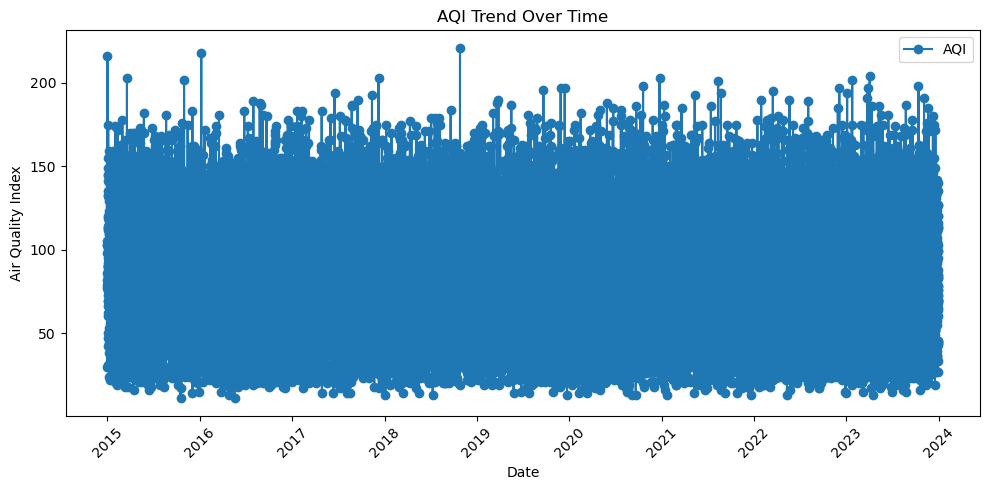

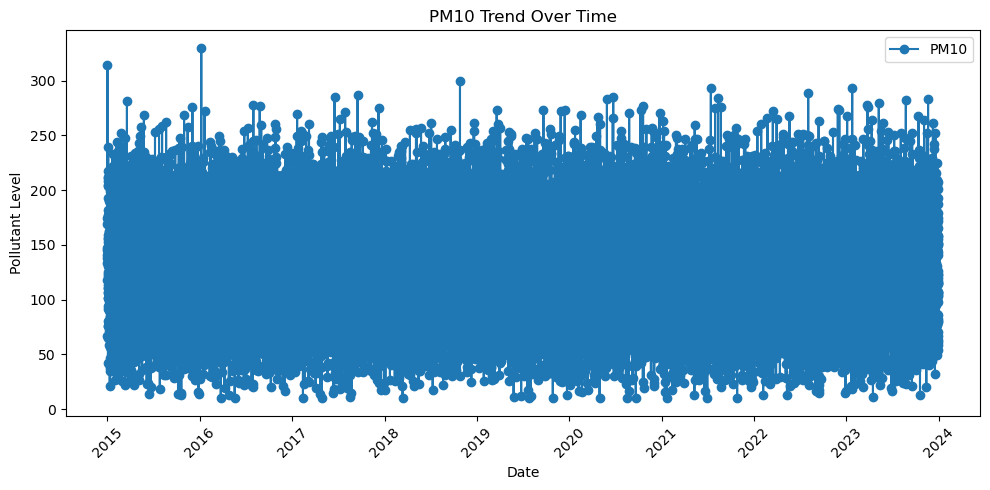

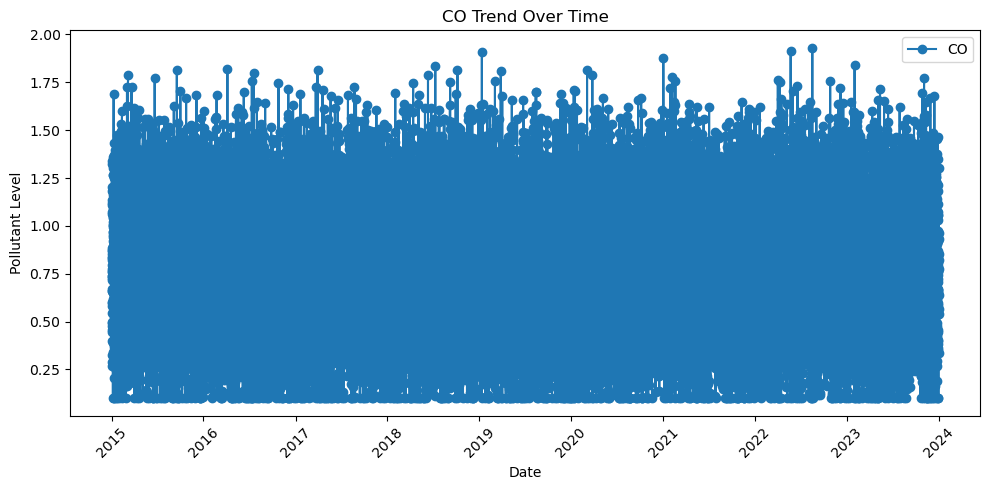

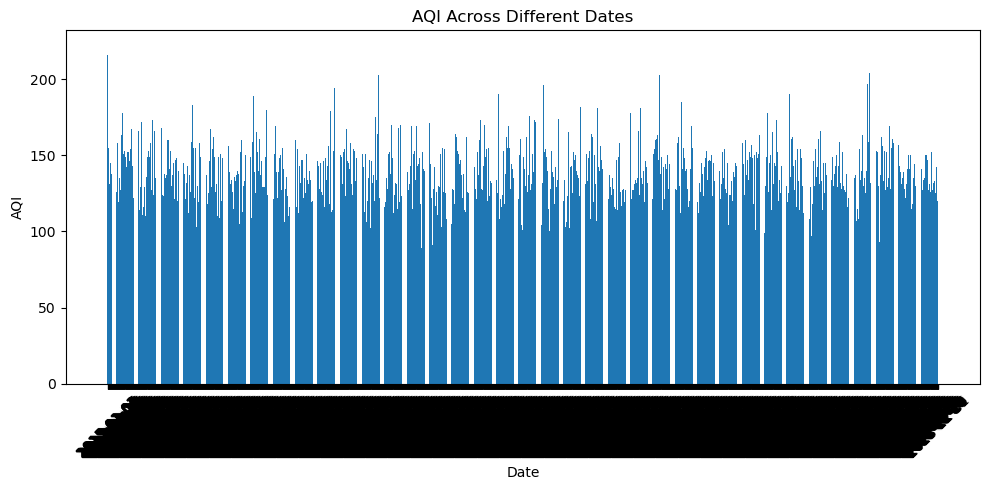

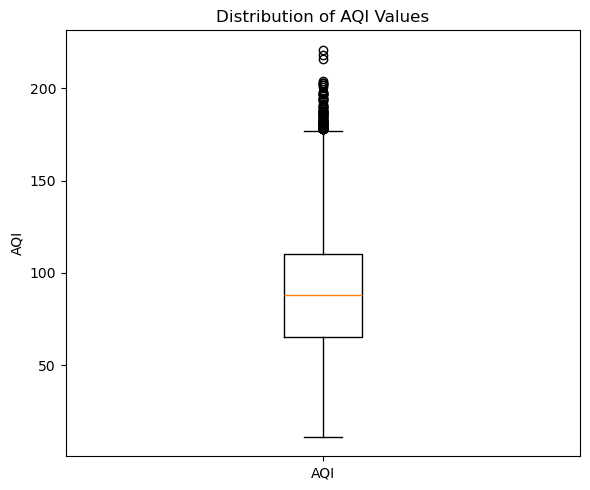

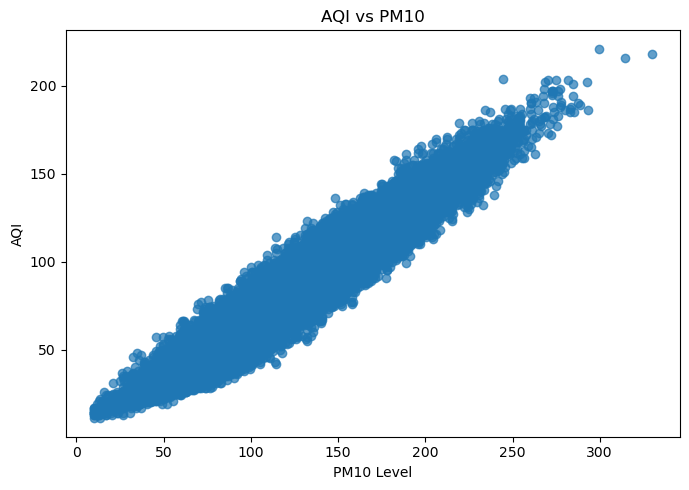

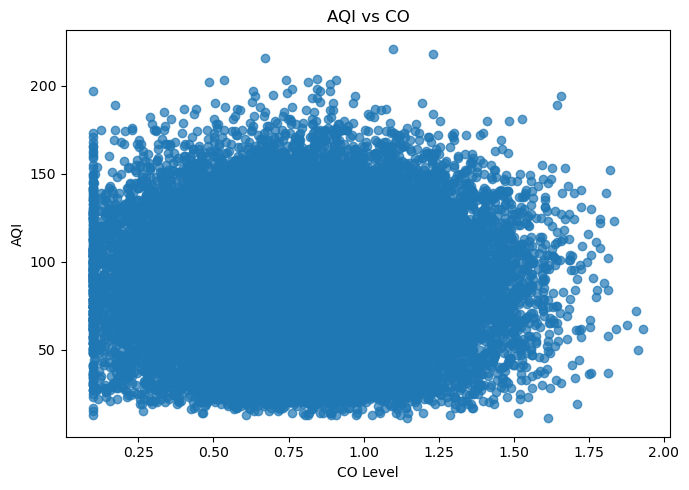


Air Quality Analysis Completed!


In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Import dataset
df = pd.read_csv("City_Air_Quality.csv")

# 2. Explore dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nColumn Names:")
print(df.columns.tolist())

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# 3. Identify relevant variables
# Expected columns: date, aqi, pm2.5, pm10, co
# Rename these below if your CSV uses different names.

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date", "aqi"])
df = df.sort_values("date")

# 4. Line plot: Overall AQI trend
plt.figure(figsize=(10, 5))
plt.plot(df["date"], df["aqi"], marker="o", label="AQI")
plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Air Quality Index")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Individual pollutant trends
pollutants = ["pm2.5", "pm10", "co"]

for pollutant in pollutants:
    if pollutant in df.columns:
        plt.figure(figsize=(10, 5))
        plt.plot(df["date"], df[pollutant],
                 marker="o", label=pollutant.upper())
        plt.title(pollutant.upper() + " Trend Over Time")
        plt.xlabel("Date")
        plt.ylabel("Pollutant Level")
        plt.legend()
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

# 6. Bar plot: AQI across dates
plt.figure(figsize=(10, 5))
plt.bar(df["date"].dt.strftime("%Y-%m-%d"), df["aqi"])
plt.title("AQI Across Different Dates")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 7. Box plot: Distribution of AQI
plt.figure(figsize=(6, 5))
plt.boxplot(df["aqi"].dropna())
plt.title("Distribution of AQI Values")
plt.ylabel("AQI")
plt.xticks([1], ["AQI"])
plt.tight_layout()
plt.show()

# 8. Scatter plots: AQI vs pollutants
for pollutant in pollutants:
    if pollutant in df.columns:
        data = df[["aqi", pollutant]].dropna()

        plt.figure(figsize=(7, 5))
        plt.scatter(data[pollutant], data["aqi"], alpha=0.7)
        plt.title("AQI vs " + pollutant.upper())
        plt.xlabel(pollutant.upper() + " Level")
        plt.ylabel("AQI")
        plt.tight_layout()
        plt.show()

# 9. Customize plots and display results
print("\nAir Quality Analysis Completed!")
